# Projeto 01 — Análise Exploratória de Dados (EDA)
## UC de Inteligência Artificial — IPCA (2026/2027)
### Otimização de Rotas de Distribuição Alimentar Local (*Pickup-and-Delivery*)

---

### Identificação do Grupo (Grupo 04 — `IA26_P01_G04`)
* **Gonçalo Correia** — Nº 22840
* **Bruno Dantas** — Nº 27958
* **Ricardo Ferreira** — Nº 25426

**Repositório Oficial:** [https://github.com/BrunoDantas1/IA26_P01_G04.git](https://github.com/BrunoDantas1/IA26_P01_G04.git)

---

## 1. Introdução e Objetivos da Análise Exploratória
Neste notebook realizamos a **Análise Exploratória de Dados (EDA)** detalhada sobre o dataset `data` do projeto. O objetivo é compreender em profundidade a estrutura relacional do problema de logística alimentar local, validar a consistência e integridade das entidades, avaliar o perfil da procura face à capacidade da frota e mapear espacialmente a distribuição geográfica dos produtores, armazéns e clientes na região de Braga e Póvoa de Varzim.

### Requisitos em Avaliação:
1. **Carregamento e Visão Geral dos CSVs**: Inspeção das 11 tabelas do sistema.
2. **Validação de Integridade Referencial**: Verificação exaustiva de Chaves Primárias (PKs) e Chaves Estrangeiras (FKs).
3. **Análise das Janelas Temporais**: Confronto entre `availability_start/end`, `delivery_start/end` e `order_datetime`.
4. **Comparação Procura vs. Capacidade**: Confronto entre peso dos pedidos e capacidade dos veículos (`weights vs. capacities`).
5. **Visualizações e Mapa Geográfico**: Localização espacial dos nós (Produtores, Centros de Recolha, Locais de Entrega) e matriz de distâncias.


In [1]:
import os
import sys

# Os notebooks vivem em notebooks/; passa para a raiz do projeto para que
# os caminhos "data" e "src" funcionem, quer se execute a partir da raiz, quer de notebooks/.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

In [2]:
# Importação de bibliotecas essenciais
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Configurações visuais do Matplotlib
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 120

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


## 2. Carregamento dos Datasets CSV
Identificamos e carregamos todas as tabelas presentes no diretório `data`.
As 11 entidades estruturais são:
* `localities.csv`: Freguesias e concelhos com coordenadas geográficas.
* `producers.csv`: Produtores locais de frescos/agrícolas.
* `products.csv`: Catálogo de produtos com unidade e peso unitário em kg.
* `collection_centers.csv`: Centro de recolha (armazém de agregação).
* `vehicles.csv`: Frota de carrinhas de distribuição e características.
* `customers.csv`: Clientes que efetuam encomendas.
* `delivery_locations.csv`: Locais de entrega (mercados municipais, residências).
* `orders.csv`: Cabeçalho das encomendas com cliente e data de submissão.
* `order_items.csv`: Linhas das encomendas com artigo, quantidade e janelas horárias.
* `locations.csv`: Catálogo unificado de paragens geográficas (tipo, ref_id, coordenadas).
* `distance_matrix.csv`: Matriz de distâncias (km) e tempos (minutos) entre todas as paragens.


In [3]:
# Determinar pasta de dados válida
data_folder = "data"
print(f"A carregar dados da pasta: {data_folder}")

# Carregamento dos 11 DataFrames
localities = pd.read_csv(f"{data_folder}/localities.csv")
producers = pd.read_csv(f"{data_folder}/producers.csv")
products = pd.read_csv(f"{data_folder}/products.csv")
centers = pd.read_csv(f"{data_folder}/collection_centers.csv")
vehicles = pd.read_csv(f"{data_folder}/vehicles.csv")
customers = pd.read_csv(f"{data_folder}/customers.csv")
delivery_locs = pd.read_csv(f"{data_folder}/delivery_locations.csv")
orders = pd.read_csv(f"{data_folder}/orders.csv")
order_items = pd.read_csv(f"{data_folder}/order_items.csv")
locations = pd.read_csv(f"{data_folder}/locations.csv")
dist_matrix = pd.read_csv(f"{data_folder}/distance_matrix.csv")

# Resumo dimensional
summary_data = [
    {"Tabela": "localities", "Linhas": len(localities), "Colunas": len(localities.columns), "Colunas Lista": list(localities.columns)},
    {"Tabela": "producers", "Linhas": len(producers), "Colunas": len(producers.columns), "Colunas Lista": list(producers.columns)},
    {"Tabela": "products", "Linhas": len(products), "Colunas": len(products.columns), "Colunas Lista": list(products.columns)},
    {"Tabela": "collection_centers", "Linhas": len(centers), "Colunas": len(centers.columns), "Colunas Lista": list(centers.columns)},
    {"Tabela": "vehicles", "Linhas": len(vehicles), "Colunas": len(vehicles.columns), "Colunas Lista": list(vehicles.columns)},
    {"Tabela": "customers", "Linhas": len(customers), "Colunas": len(customers.columns), "Colunas Lista": list(customers.columns)},
    {"Tabela": "delivery_locations", "Linhas": len(delivery_locs), "Colunas": len(delivery_locs.columns), "Colunas Lista": list(delivery_locs.columns)},
    {"Tabela": "orders", "Linhas": len(orders), "Colunas": len(orders.columns), "Colunas Lista": list(orders.columns)},
    {"Tabela": "order_items", "Linhas": len(order_items), "Colunas": len(order_items.columns), "Colunas Lista": list(order_items.columns)},
    {"Tabela": "locations", "Linhas": len(locations), "Colunas": len(locations.columns), "Colunas Lista": list(locations.columns)},
    {"Tabela": "distance_matrix", "Linhas": len(dist_matrix), "Colunas": len(dist_matrix.columns), "Colunas Lista": list(dist_matrix.columns)},
]
pd.DataFrame(summary_data)

A carregar dados da pasta: data


,Tabela,Linhas,Colunas,Colunas Lista
0,localities,49,6,"[locality_id, name, municipality, district, la..."
1,producers,5,6,"[producer_id, name, locality_id, address, phon..."
2,products,23,6,"[product_id, producer_id, name, category, unit..."
3,collection_centers,1,5,"[center_id, name, locality_id, address, capaci..."
4,vehicles,2,6,"[vehicle_id, plate, center_id, capacity_kg, re..."
5,customers,8,5,"[customer_id, name, locality_id, phone, email]"
6,delivery_locations,6,5,"[delivery_location_id, name, locality_id, addr..."
7,orders,10,5,"[order_id, customer_id, delivery_location_id, ..."
8,order_items,23,8,"[order_item_id, order_id, product_id, quantity..."
9,locations,12,7,"[location_id, location_type, ref_id, name, mun..."


## 3. Validação de Integridade Referencial (PKs e FKs)
Testamos rigorosamente a integridade do esquema da base de dados:
1. **Unicidade das Chaves Primárias (PKs)**: Nenhuma tabela pode conter chaves duplicadas ou nulas.
2. **Integridade das Chaves Estrangeiras (FKs)**: Todas as referências cruzadas entre tabelas devem apontar para registos existentes e válidos.


In [4]:
# 1. Validação de Chaves Primárias
pk_definitions = [
    ("localities", localities, "locality_id"),
    ("producers", producers, "producer_id"),
    ("products", products, "product_id"),
    ("collection_centers", centers, "center_id"),
    ("vehicles", vehicles, "vehicle_id"),
    ("customers", customers, "customer_id"),
    ("delivery_locations", delivery_locs, "delivery_location_id"),
    ("orders", orders, "order_id"),
    ("order_items", order_items, "order_item_id"),
    ("locations", locations, "location_id"),
]

pk_results = []
for name, df, pk in pk_definitions:
    total = len(df)
    unique = df[pk].nunique()
    nulls = df[pk].isnull().sum()
    valid = (total == unique) and (nulls == 0)
    pk_results.append({
        "Tabela": name,
        "Chave Primária": pk,
        "Total Registos": total,
        "Registos Únicos": unique,
        "Nulos": nulls,
        "Status PK": "✓ VÁLIDA" if valid else "✗ ERRO"
    })

display(pd.DataFrame(pk_results))

# A matriz tem chave composta, não um identificador simples.
assert not dist_matrix[['origin_location_id', 'destination_location_id']].isna().any().any()
assert not dist_matrix.duplicated(['origin_location_id', 'destination_location_id']).any()
assert all(row['Status PK'] == '✓ VÁLIDA' for row in pk_results)


,Tabela,Chave Primária,Total Registos,Registos Únicos,Nulos,Status PK
0,localities,locality_id,49,49,0,✓ VÁLIDA
1,producers,producer_id,5,5,0,✓ VÁLIDA
2,products,product_id,23,23,0,✓ VÁLIDA
3,collection_centers,center_id,1,1,0,✓ VÁLIDA
4,vehicles,vehicle_id,2,2,0,✓ VÁLIDA
5,customers,customer_id,8,8,0,✓ VÁLIDA
6,delivery_locations,delivery_location_id,6,6,0,✓ VÁLIDA
7,orders,order_id,10,10,0,✓ VÁLIDA
8,order_items,order_item_id,23,23,0,✓ VÁLIDA
9,locations,location_id,12,12,0,✓ VÁLIDA


In [5]:
# 2. Validação de Chaves Estrangeiras
fk_definitions = [
    (producers, "producers.locality_id", "locality_id", localities, "locality_id"),
    (centers, "collection_centers.locality_id", "locality_id", localities, "locality_id"),
    (delivery_locs, "delivery_locations.locality_id", "locality_id", localities, "locality_id"),
    (customers, "customers.locality_id", "locality_id", localities, "locality_id"),
    (vehicles, "vehicles.center_id", "center_id", centers, "center_id"),
    (products, "products.producer_id", "producer_id", producers, "producer_id"),
    (orders, "orders.customer_id", "customer_id", customers, "customer_id"),
    (orders, "orders.delivery_location_id", "delivery_location_id", delivery_locs, "delivery_location_id"),
    (order_items, "order_items.order_id", "order_id", orders, "order_id"),
    (order_items, "order_items.product_id", "product_id", products, "product_id"),
    (dist_matrix, "distance_matrix (origem)", "origin_location_id", locations, "location_id"),
    (dist_matrix, "distance_matrix (destino)", "destination_location_id", locations, "location_id"),
]

fk_results = []
for src_df, src_label, src_col, tgt_df, tgt_col in fk_definitions:
    invalid_mask = ~src_df[src_col].isin(tgt_df[tgt_col])
    invalids = invalid_mask.sum()
    fk_results.append({
        "Relação (FK)": src_label,
        "Chave Origem": src_col,
        "Tabela Destino": tgt_col,
        "Violações": invalids,
        "Status FK": "✓ ÍNTEGRA" if invalids == 0 else f"✗ {invalids} ÓRFÃOS"
    })

display(pd.DataFrame(fk_results))

# Validar também as referências polimórficas do catálogo unificado.
for kind, frame, key in [('producer', producers, 'producer_id'),
                         ('collection_center', centers, 'center_id'),
                         ('delivery_location', delivery_locs, 'delivery_location_id')]:
    refs = locations.loc[locations.location_type == kind, 'ref_id']
    assert refs.is_unique and set(refs) == set(frame[key])
assert locations.location_type.isin(['producer', 'collection_center', 'delivery_location']).all()
assert all(row['Violações'] == 0 for row in fk_results)
assert len(dist_matrix) == len(locations) * (len(locations) - 1)
assert (dist_matrix.origin_location_id != dist_matrix.destination_location_id).all()


,Relação (FK),Chave Origem,Tabela Destino,Violações,Status FK
0,producers.locality_id,locality_id,locality_id,0,✓ ÍNTEGRA
1,collection_centers.locality_id,locality_id,locality_id,0,✓ ÍNTEGRA
2,delivery_locations.locality_id,locality_id,locality_id,0,✓ ÍNTEGRA
3,customers.locality_id,locality_id,locality_id,0,✓ ÍNTEGRA
4,vehicles.center_id,center_id,center_id,0,✓ ÍNTEGRA
5,products.producer_id,producer_id,producer_id,0,✓ ÍNTEGRA
6,orders.customer_id,customer_id,customer_id,0,✓ ÍNTEGRA
7,orders.delivery_location_id,delivery_location_id,delivery_location_id,0,✓ ÍNTEGRA
8,order_items.order_id,order_id,order_id,0,✓ ÍNTEGRA
9,order_items.product_id,product_id,product_id,0,✓ ÍNTEGRA


### Conclusão sobre Integridade:
* As 10 tabelas com identificador simples têm chaves únicas e sem nulos. A matriz também tem pares origem/destino únicos.
* As 12 relações FK verificadas têm zero órfãos. Os três tipos de `locations.ref_id` correspondem às entidades de origem.
* `locations.csv` unifica produtores (1–5), centro (6) e locais de entrega (7–12). A matriz tem 132 pares dirigidos, sem diagonal: 12 × 11.
* Estas verificações estruturais não garantem a viabilidade temporal dos pedidos.


## 4. Análise de Carga: Procura vs. Capacidade da Frota
Examinamos o volume de mercadoria requisitado em cada pedido, comparando-o com a capacidade máxima da frota de veículos e do centro de recolha.


In [6]:
# Cruzar artigos com encomendas e catálogo de produtos
merged_demand = order_items.merge(orders, on="order_id").merge(products, on="product_id")
merged_demand["weight_kg"] = merged_demand["quantity"] * merged_demand["unit_weight_kg"]

total_demand_kg = merged_demand["weight_kg"].sum()
max_item_kg = merged_demand["weight_kg"].max()
min_item_kg = merged_demand["weight_kg"].min()
mean_item_kg = merged_demand["weight_kg"].mean()

print(f"Procura Total Acumulada ({len(merged_demand)} itens): {total_demand_kg:.2f} kg")
print(f"Peso Máximo de um Artigo: {max_item_kg:.2f} kg | Mínimo: {min_item_kg:.2f} kg | Médio: {mean_item_kg:.2f} kg")

# Tabela comparativa com a capacidade dos veículos
fleet_cap = vehicles[["vehicle_id", "plate", "capacity_kg"]].copy()
fleet_cap["Carga Total Dataset (%)"] = (total_demand_kg / fleet_cap["capacity_kg"] * 100).round(2)
display(fleet_cap)

daily_demand = merged_demand.groupby(pd.to_datetime(merged_demand['availability_start']).dt.date)['weight_kg'].sum()
peak_day = daily_demand.idxmax()
peak_kg = daily_demand.max()
assert len(merged_demand) == 23
assert np.isclose(total_demand_kg, 248.96)
assert np.isclose(peak_kg, 43.58)
assert str(peak_day) == '2026-10-19'
assert vehicles['refrigerated'].eq(0).all()
print(f'Maior procura por data de abertura da recolha: {peak_day}, {peak_kg:.2f} kg')


Procura Total Acumulada (23 itens): 248.96 kg
Peso Máximo de um Artigo: 24.60 kg | Mínimo: 0.90 kg | Médio: 10.82 kg


,vehicle_id,plate,capacity_kg,Carga Total Dataset (%)
0,1,ZG-06-DP,1444.7,17.23
1,2,TY-74-YA,1009.8,24.65


Maior procura por data de abertura da recolha: 2026-10-19, 43.58 kg


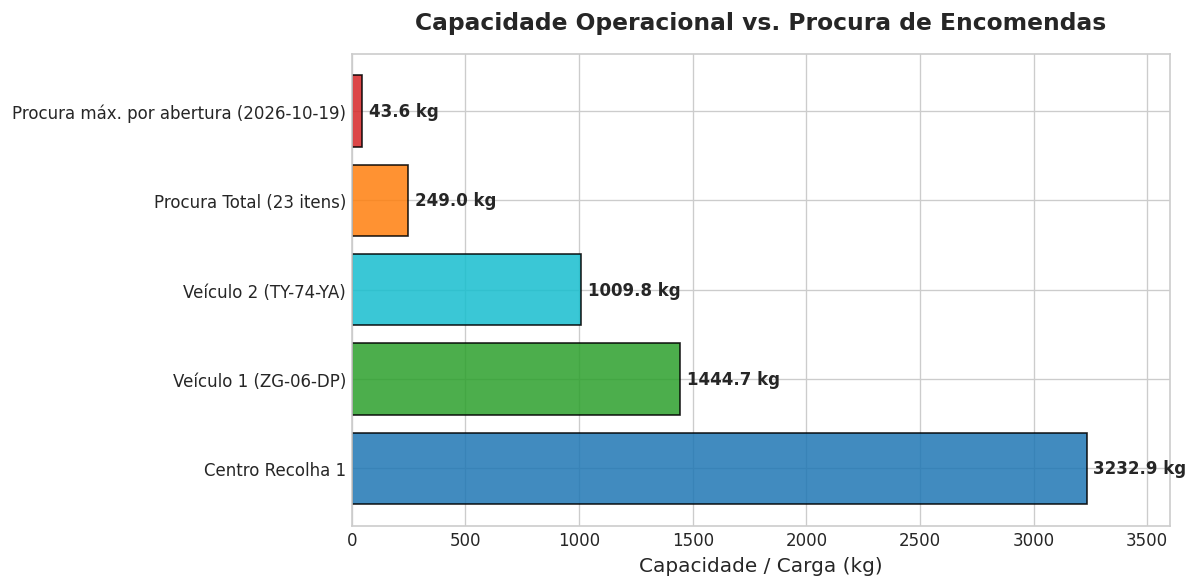

In [7]:
# Gráfico Comparativo: Capacidade vs. Procura
fig, ax = plt.subplots(figsize=(10, 5))

entities = ['Centro Recolha 1', 'Veículo 1 (ZG-06-DP)', 'Veículo 2 (TY-74-YA)', 'Procura Total (23 itens)', f'Procura máx. por abertura ({peak_day})']
capacities = [centers.iloc[0]['capacity_kg'], vehicles.iloc[0]['capacity_kg'], vehicles.iloc[1]['capacity_kg'], total_demand_kg, peak_kg]
colors = ['#1f77b4', '#2ca02c', '#17becf', '#ff7f0e', '#d62728']

bars = ax.barh(entities, capacities, color=colors, edgecolor='black', alpha=0.85)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 30, bar.get_y() + bar.get_height()/2, f'{w:.1f} kg', ha='left', va='center', fontweight='bold', fontsize=10)

ax.set_title('Capacidade Operacional vs. Procura de Encomendas', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Capacidade / Carga (kg)', fontsize=12)
ax.set_xlim(0, 3600)
plt.tight_layout()
plt.show()

### Conclusão sobre Cargas e Capacidades:
1. Veículos: **1444,70 kg** e **1009,80 kg**, ambos sem refrigeração. Centro: **3232,90 kg**.
2. Procura agregada: **248,96 kg**, em **23 artigos de 10 encomendas**. Pesos unitários requisitados: mínimo **0,90 kg**, máximo **24,60 kg**, média **10,82 kg**.
3. A procura equivale a **17,23%** da capacidade do veículo 1 ou **24,65%** do veículo 2. São capacidades em massa, não em volume.
4. O máximo por data de abertura da recolha é **43,58 kg em 19/10/2026**. Esta agregação não constitui um plano diário viável.
5. A capacidade em kg é suficiente para o peso agregado; isso não demonstra uma rota única viável. É necessário validar tempos, precedência e carga em cada passo.


## 5. Análise Crítica das Janelas Temporais
Avaliamos a consistência cronológica entre:
* `order_datetime`: Momento em que o cliente submete o pedido.
* `availability_start` e `availability_end`: Janela em que o produtor tem o bem disponível para recolha.
* `delivery_start` e `delivery_end`: Janela em que o cliente exige a receção da encomenda.


In [8]:
# Conversão para timestamps
merged_demand['avail_start_dt'] = pd.to_datetime(merged_demand['availability_start'])
merged_demand['avail_end_dt'] = pd.to_datetime(merged_demand['availability_end'])
merged_demand['deliv_start_dt'] = pd.to_datetime(merged_demand['delivery_start'])
merged_demand['deliv_end_dt'] = pd.to_datetime(merged_demand['delivery_end'])
merged_demand['order_dt'] = pd.to_datetime(merged_demand['order_datetime'])

# Momento efetivo em que a encomenda está pronta para recolha
merged_demand['ready_time'] = merged_demand[['avail_start_dt', 'order_dt']].max(axis=1)

# Validações lógicas
v1 = (merged_demand['avail_start_dt'] <= merged_demand['avail_end_dt']).all()
v2 = (merged_demand['deliv_start_dt'] <= merged_demand['deliv_end_dt']).all()
v3 = (merged_demand['avail_start_dt'] <= merged_demand['deliv_end_dt']).all()

# Detetar inconsistências de pedidos colocados após o fecho da disponibilidade
temporal_anomalies = merged_demand[merged_demand['ready_time'] > merged_demand['avail_end_dt']]
valid_temporal_items = merged_demand[merged_demand['ready_time'] <= merged_demand['avail_end_dt']]

print(f"availability_start <= availability_end em todos os artigos: {v1}")
print(f"delivery_start <= delivery_end em todos os artigos: {v2}")
print(f"availability_start <= delivery_end em todos os artigos: {v3}")
print(f"Artigos com prontidão dentro da janela de recolha: {len(valid_temporal_items)} / {len(merged_demand)}")
print(f"Artigos com data de encomenda posterior à disponibilidade: {len(temporal_anomalies)} / {len(merged_demand)}")

assert v1 and v2 and v3
assert len(temporal_anomalies) == 12
assert len(valid_temporal_items) == 11
assert sorted(temporal_anomalies.order_item_id) == [1, 3, 4, 9, 13, 14, 15, 16, 18, 20, 21, 23]
delivery_hours = (merged_demand.deliv_end_dt - merged_demand.deliv_start_dt).dt.total_seconds() / 3600
assert delivery_hours.min() == 1 and delivery_hours.max() == 4
print(f'Janelas de entrega: {delivery_hours.min():.0f} a {delivery_hours.max():.0f} horas')
print('Artigos candidatos por prontidão:', sorted(valid_temporal_items.order_item_id))


availability_start <= availability_end em todos os artigos: True
delivery_start <= delivery_end em todos os artigos: True
availability_start <= delivery_end em todos os artigos: True
Artigos com prontidão dentro da janela de recolha: 11 / 23
Artigos com data de encomenda posterior à disponibilidade: 12 / 23
Janelas de entrega: 1 a 4 horas
Artigos candidatos por prontidão: [2, 5, 6, 7, 8, 10, 11, 12, 17, 19, 22]


In [9]:
# Detalhe das anomalias temporais encontradas no dataset sintético
print("Exemplo de anomalias encontradas no dataset:")
temporal_anomalies[['order_item_id', 'order_id', 'order_datetime', 'availability_start', 'availability_end', 'delivery_start']].head(5)

Exemplo de anomalias encontradas no dataset:


,order_item_id,order_id,order_datetime,availability_start,availability_end,delivery_start
0,1,1,2026-10-15 10:45:00,2026-10-13 08:00:00,2026-10-13 11:00:00,2026-10-13 13:00:00
2,3,2,2026-10-17 13:00:00,2026-10-07 09:00:00,2026-10-07 11:00:00,2026-10-07 12:00:00
3,4,2,2026-10-17 13:00:00,2026-10-09 07:00:00,2026-10-09 13:00:00,2026-10-09 12:00:00
8,9,4,2026-10-15 10:30:00,2026-10-12 09:00:00,2026-10-12 13:00:00,2026-10-12 14:00:00
12,13,6,2026-10-10 10:45:00,2026-10-09 12:15:00,2026-10-09 15:15:00,2026-10-10 13:15:00


### Consequências para o Planeamento:
* **12 artigos** têm `order_datetime > availability_end`: 1, 3, 4, 9, 13, 14, 15, 16, 18, 20, 21 e 23. Não é possível recolhê-los dentro da janela, mesmo chegando antes de abrir.
* **11 artigos** têm `ready_time = max(order_datetime, availability_start) <= availability_end`: 2, 5, 6, 7, 8, 10, 11, 12, 17, 19 e 22. Este teste é necessário, mas não garante uma rota viável com deslocações e entregas.
* Encomendar após a abertura, mas antes do fecho, é permitido. A anomalia é a prontidão após o fecho.
* Os artigos 7, 10 e 22 abrem a recolha em **19/10/2026**. As suas janelas não garantem sincronização nem uma única rota viável.
* As janelas de entrega duram **1 a 4 horas**; algumas ocorrem no dia seguinte à disponibilidade. O validador mantém todos os artigos e rejeita os inviáveis, sem os eliminar silenciosamente.


## 6. Mapeamento Espacial das Localizações
Construímos a representação cartográfica dos locais de operação no distrito de Braga e Póvoa de Varzim a partir das coordenadas geográficas (latitude e longitude) de `locations.csv`.


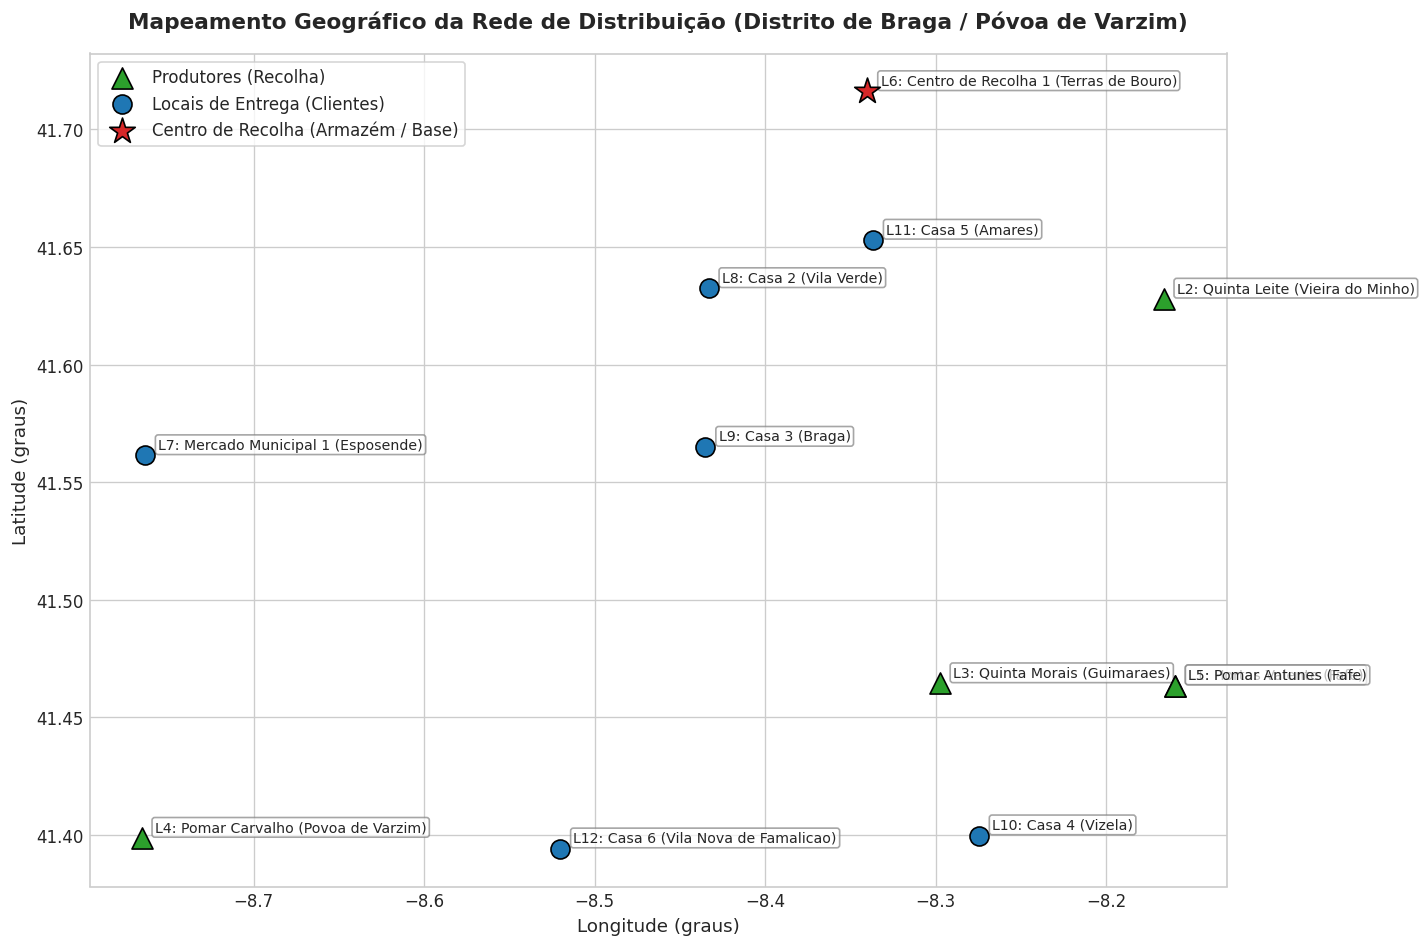

In [10]:
# Mapeamento geográfico das paragens
fig, ax = plt.subplots(figsize=(12, 8))

# Separar por tipo de nó
centers_pts = locations[locations['location_type'] == 'collection_center']
producers_pts = locations[locations['location_type'] == 'producer']
delivery_pts = locations[locations['location_type'] == 'delivery_location']

# Plot dos pontos
ax.scatter(producers_pts['longitude'], producers_pts['latitude'], color='#2ca02c', s=160, marker='^', label='Produtores (Recolha)', zorder=5, edgecolor='black')
ax.scatter(delivery_pts['longitude'], delivery_pts['latitude'], color='#1f77b4', s=130, marker='o', label='Locais de Entrega (Clientes)', zorder=5, edgecolor='black')
ax.scatter(centers_pts['longitude'], centers_pts['latitude'], color='#d62728', s=260, marker='*', label='Centro de Recolha (Armazém / Base)', zorder=6, edgecolor='black')

# Adicionar rótulos aos nós
for _, row in locations.iterrows():
    ax.annotate(
        f"L{row['location_id']}: {row['name']} ({row['municipality']})",
        (row['longitude'], row['latitude']),
        textcoords="offset points",
        xytext=(8, 4),
        fontsize=8.5,
        fontweight='medium',
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.7, edgecolor="gray")
    )

ax.set_title("Mapeamento Geográfico da Rede de Distribuição (Distrito de Braga / Póvoa de Varzim)", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Longitude (graus)", fontsize=11)
ax.set_ylabel("Latitude (graus)", fontsize=11)
ax.legend(loc="upper left", frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

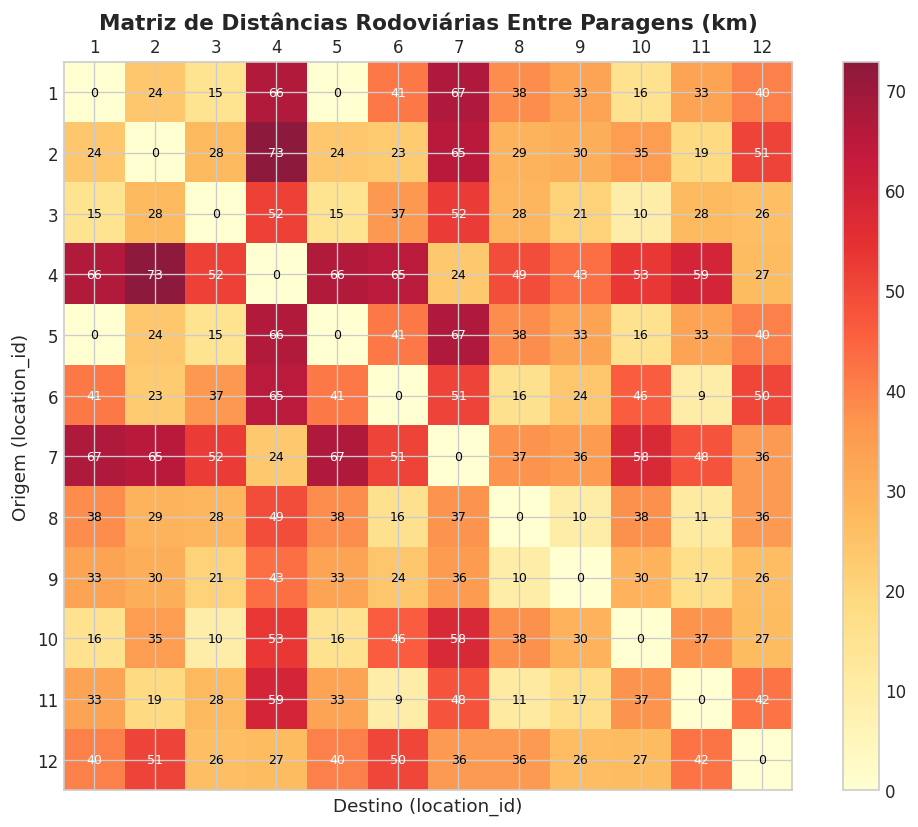

In [11]:
# Visualização da Matriz de Distâncias (Heatmap)
pivoted_dist = dist_matrix.pivot(index='origin_location_id', columns='destination_location_id', values='distance_km').fillna(0)

fig, ax = plt.subplots(figsize=(9, 7))
cax = ax.matshow(pivoted_dist, cmap='YlOrRd', alpha=0.9)

fig.colorbar(cax)
ax.set_xticks(range(len(pivoted_dist.columns)))
ax.set_yticks(range(len(pivoted_dist.index)))
ax.set_xticklabels(pivoted_dist.columns)
ax.set_yticklabels(pivoted_dist.index)

# Adicionar valores nas células
for i in range(len(pivoted_dist.index)):
    for j in range(len(pivoted_dist.columns)):
        val = pivoted_dist.iloc[i, j]
        ax.text(j, i, f"{val:.0f}", ha="center", va="center", color="black" if val < 40 else "white", fontsize=7.5)

ax.set_title("Matriz de Distâncias Rodoviárias Entre Paragens (km)", fontsize=13, fontweight='bold', pad=20)
ax.set_xlabel("Destino (location_id)", fontsize=11)
ax.set_ylabel("Origem (location_id)", fontsize=11)
plt.tight_layout()
plt.show()

## 7. Síntese Executiva da Análise Exploratória
1. **Estrutura**: 11 CSV, 12 localizações, 132 pares dirigidos fora da diagonal; as chaves e referências verificadas são válidas.
2. **Capacidade**: 248,96 kg agregados, face a veículos de 1444,70 kg e 1009,80 kg. Nenhum é refrigerado; o centro tem capacidade de 3232,90 kg.
3. **Tempo**: 12 artigos têm prontidão após o fecho; os outros 11 são candidatos, sujeitos aos tempos de viagem e restantes restrições.
4. **Geografia**: o centro fica em Terras de Bouro. As distâncias do centro aos seis destinos variam entre 9,14 km e 50,94 km (`distance_matrix.csv`).
5. **Modelo**: `model.py` valida início e regresso explícitos ao depósito, precedência, carga, janelas após espera e ligações em todos os troços. O custo usa a mesma validação.
6. **Fase 2**: selecionar subconjuntos apenas após validação de rotas; as contagens e a capacidade agregada não demonstram que todo o dataset seja servível.
